# Decay exponents against temperature

A short version of [density_matrix_comparison.ipynb](density_matrix_comparison.ipynb). It uses the same raw files, weighted fits and interval, with plain calculations. See the main notebook to walk through the matrix plots, an individual fit, chi-squared and winding.

Errors neglect covariance between directions, production windows and distances. Chi-squared and nominal p-values are diagonal approximations.


## Imports and temperatures


In [1]:
from pathlib import Path
import h5py
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.stats import chi2

root = Path.cwd()
for folder in (root, *root.parents):
    if (folder / 'results' / 'clean_Rb87').is_dir():
        root = folder
        break
results = root / 'results'

sizes = [32, 64, 128]
betas = [.70, .60, .52, .45, .39, .35, .32, .30, .28]
T = 1 / np.array(betas)
colours = ['tab:green', 'tab:blue', 'tab:orange']
plt.rcParams.update({'figure.figsize': (7, 4.5), 'figure.dpi': 110})

## Read the measurements


In [2]:
density_runs, density_error_runs, histograms = {}, {}, {}
winding_runs, winding_error_runs, winding_samples = {}, {}, {}

for L in sizes:
    for beta in betas:
        name = f'l{L}t{round(100 * beta):03d}'
        folder = results / 'cleanRbRDM' / name
        if not folder.is_dir():
            folder = results / 'clean_Rb87' / name
        files = sorted(folder.glob('*prod[0-9][0-9].h5'))
        assert len(files) == 3, f'Expected three productions in {folder}'

        density_runs[L, beta] = np.zeros((3, L, L))
        density_error_runs[L, beta] = np.zeros((3, L, L))
        histograms[L, beta] = np.zeros(3)
        winding_runs[L, beta] = np.zeros((3, 2))
        winding_error_runs[L, beta] = np.zeros((3, 2))
        winding_samples[L, beta] = np.zeros(3)
        for p, file in enumerate(files):
            with h5py.File(file, 'r') as f:
                density = f['simulation/results/Density_Matrix']
                density_runs[L, beta][p] = density['mean/value'][()].reshape(L, L)
                density_error_runs[L, beta][p] = density['mean/error'][()].reshape(L, L)
                histograms[L, beta][p] = density['count'][()]
                winding = f['simulation/results/Winding_number_squared']
                winding_runs[L, beta][p] = winding['mean/value'][()]
                winding_error_runs[L, beta][p] = winding['mean/error'][()]
                winding_samples[L, beta][p] = winding['count'][()]
        print(name, folder.parent.name, histograms[L, beta].astype(int))

l32t070 clean_Rb87 [146 120 120]
l32t060 clean_Rb87 [144 144 144]
l32t052 clean_Rb87 [180 169 180]
l32t045 clean_Rb87 [285 287 287]
l32t039 clean_Rb87 [344 347 347]
l32t035 clean_Rb87 [407 421 420]
l32t032 clean_Rb87 [468 472 470]
l32t030 clean_Rb87 [466 470 471]
l32t028 clean_Rb87 [471 468 470]
l64t070 cleanRbRDM [158 139 132]
l64t060 cleanRbRDM [191 188 189]
l64t052 clean_Rb87 [48 48 48]
l64t045 clean_Rb87 [72 72 72]
l64t039 clean_Rb87 [ 96  96 102]
l64t035 clean_Rb87 [ 98 106 108]
l64t032 clean_Rb87 [187 187 177]
l64t030 clean_Rb87 [281 286 195]
l64t028 clean_Rb87 [469 466 467]
l128t070 cleanRbRDM [33 34 33]
l128t060 cleanRbRDM [48 46 43]
l128t052 cleanRbRDM [61 63 65]
l128t045 cleanRbRDM [92 82 80]
l128t039 cleanRbRDM [119 110 109]
l128t035 cleanRbRDM [166 160 160]
l128t032 clean_Rb87 [41 41 40]
l128t030 clean_Rb87 [ 47  97 103]
l128t028 clean_Rb87 [382 405 447]


## Count-weighted averages and propagated errors


In [3]:
G, G_error, W, W_error = {}, {}, {}, {}
for L in sizes:
    for beta in betas:
        weights = histograms[L, beta] / histograms[L, beta].sum()
        G[L, beta] = np.average(density_runs[L, beta], axis=0, weights=weights)
        G_error[L, beta] = np.sqrt(np.sum(
            (weights[:, None, None] * density_error_runs[L, beta])**2, axis=0))

        weights = winding_samples[L, beta] / winding_samples[L, beta].sum()
        W[L, beta] = np.average(winding_runs[L, beta], axis=0, weights=weights)
        W_error[L, beta] = np.sqrt(np.sum(
            (weights[:, None] * winding_error_runs[L, beta])**2, axis=0))

## Average the four axis directions


In [4]:
distance, profile, profile_error = {}, {}, {}
for L in sizes:
    r = np.arange(1, L // 2)
    distance[L] = r
    for beta in betas:
        matrix = G[L, beta]
        error = G_error[L, beta]
        profile[L, beta] = (matrix[0, r] + matrix[0, -r]
                            + matrix[r, 0] + matrix[-r, 0]) / 4
        profile_error[L, beta] = np.sqrt(error[0, r]**2 + error[0, -r]**2
                                         + error[r, 0]**2 + error[-r, 0]**2) / 4

## Fit both models at every temperature

Fit raw G(r), using max(3, L/16) <= r <= L/4. Both models have two parameters. The exponential parameter xi is a decay length; the algebraic eta is an exponent.


In [5]:
algebraic = lambda r, A, eta: A * r**(-eta)
exponential = lambda r, A, xi: A * np.exp(-r / xi)


In [6]:
alg_parameters = np.zeros((3, len(betas), 2))
exp_parameters = np.zeros((3, len(betas), 2))
alg_chi2 = np.zeros((3, len(betas)))
exp_chi2 = np.zeros((3, len(betas)))
degrees_of_freedom = np.zeros((3, len(betas)), dtype=int)

for i, L in enumerate(sizes):
    for j, beta in enumerate(betas):
        r = distance[L]
        use = (r >= max(3, L // 16)) & (r <= L // 4)
        r_fit = r[use]
        y_fit = profile[L, beta][use]
        sigma_fit = profile_error[L, beta][use]
        alg_parameters[i, j], _ = curve_fit(algebraic, r_fit, y_fit, p0=(2, .2),
            sigma=sigma_fit, absolute_sigma=True, bounds=(0, np.inf))
        exp_parameters[i, j], _ = curve_fit(exponential, r_fit, y_fit, p0=(2, L),
            sigma=sigma_fit, absolute_sigma=True, bounds=(0, np.inf))
        alg_chi2[i, j] = np.sum(((y_fit - algebraic(r_fit, *alg_parameters[i, j])) / sigma_fit)**2)
        exp_chi2[i, j] = np.sum(((y_fit - exponential(r_fit, *exp_parameters[i, j])) / sigma_fit)**2)
        degrees_of_freedom[i, j] = len(r_fit) - 2

alg_reduced = alg_chi2 / degrees_of_freedom
exp_reduced = exp_chi2 / degrees_of_freedom
alg_p_nominal = chi2.sf(alg_chi2, degrees_of_freedom)
exp_p_nominal = chi2.sf(exp_chi2, degrees_of_freedom)
print('Finished: 27 points, two models at each point.')

Finished: 27 points, two models at each point.


## Algebraic exponent against temperature


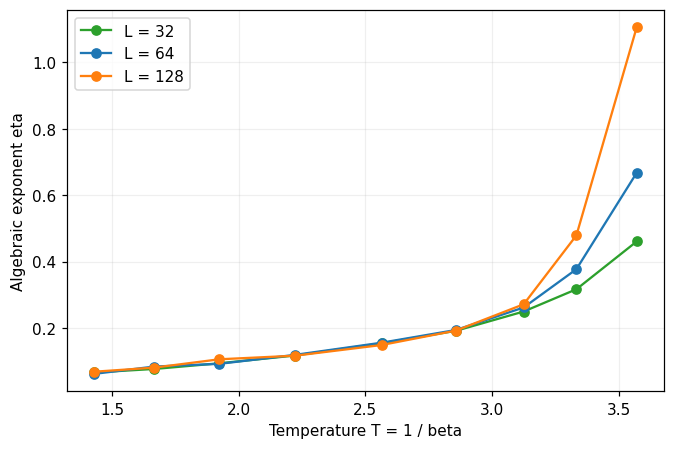

In [7]:
plt.figure()
for i, L in enumerate(sizes):
    plt.plot(T, alg_parameters[i, :, 1], 'o-', color=colours[i], label=f'L = {L}')
plt.xlabel('Temperature T = 1 / beta')
plt.ylabel('Algebraic exponent eta')
plt.legend()
plt.grid(alpha=.2)
plt.show()

## Exponential decay length against temperature


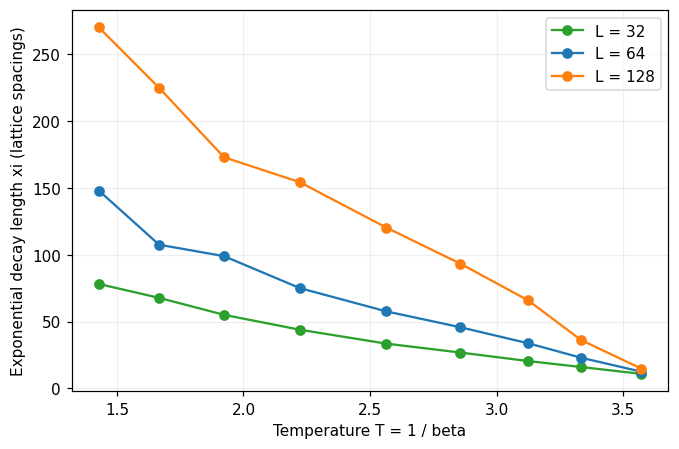

In [8]:
plt.figure()
for i, L in enumerate(sizes):
    plt.plot(T, exp_parameters[i, :, 1], 'o-', color=colours[i], label=f'L = {L}')
plt.xlabel('Temperature T = 1 / beta')
plt.ylabel('Exponential decay length xi (lattice spacings)')
plt.legend()
plt.grid(alpha=.2)
plt.show()

## Chi-squared against temperature


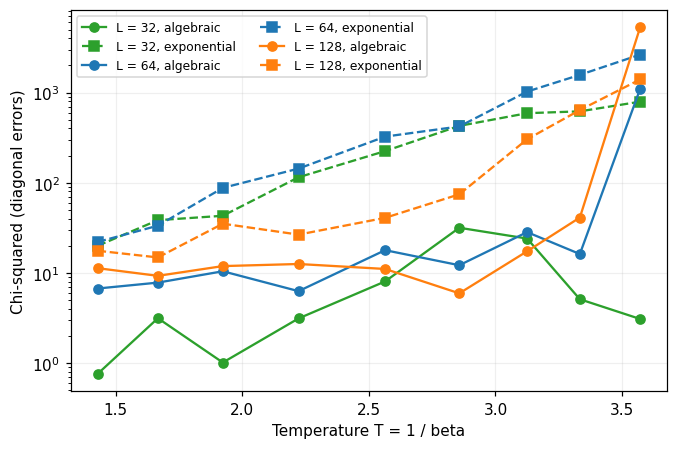

In [9]:
plt.figure()
for i, L in enumerate(sizes):
    plt.plot(T, alg_chi2[i], 'o-', color=colours[i], label=f'L = {L}, algebraic')
    plt.plot(T, exp_chi2[i], 's--', color=colours[i], label=f'L = {L}, exponential')
plt.yscale('log')

plt.xlabel('Temperature T = 1 / beta')
plt.ylabel('Chi-squared (diagonal errors)')
plt.legend(ncol=2, fontsize=8)
plt.grid(alpha=.2)
plt.show()

## Reduced chi-squared against temperature


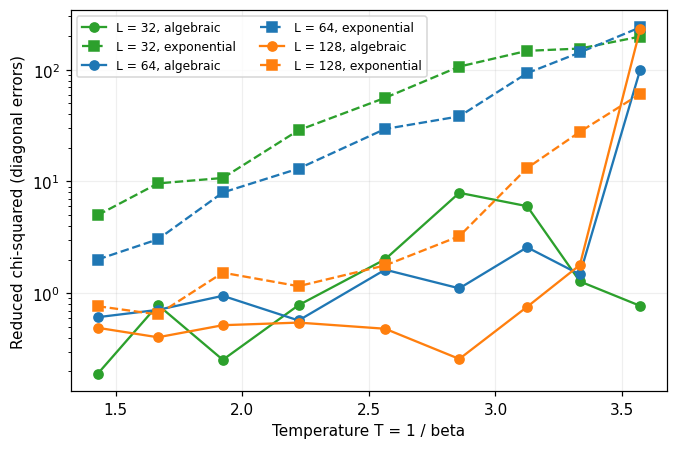

In [10]:
plt.figure()
for i, L in enumerate(sizes):
    plt.plot(T, alg_reduced[i], 'o-', color=colours[i], label=f'L = {L}, algebraic')
    plt.plot(T, exp_reduced[i], 's--', color=colours[i], label=f'L = {L}, exponential')
plt.yscale('log')

plt.xlabel('Temperature T = 1 / beta')
plt.ylabel('Reduced chi-squared (diagonal errors)')
plt.legend(ncol=2, fontsize=8)
plt.grid(alpha=.2)
plt.show()